# TP 1 — Construire un pipeline NLP classique

**Cours NLP et Transformers — CY Tech**

---

## Avant de commencer

**Faites tout de suite : `Fichier` → `Enregistrer une copie dans Drive`.**
Sans cela vous travaillez sur une copie temporaire et vous perdrez tout en fermant l'onglet.

## Objectif

Construire un pipeline de classification de texte **complet et correctement évalué**, de bout en bout :

`texte brut → prétraitement → représentation → modèle → mesure`

Le but n'est pas d'obtenir le meilleur score. Le but est que **chaque décision du pipeline soit justifiée** et que le score annoncé soit crédible.

## Ce qui est attendu

1. Un jeu de données étiqueté construit à partir du corpus brut
2. Un prétraitement et une représentation TF–IDF
3. Une **baseline** avant tout modèle
4. **Au moins deux modèles** de machine learning comparés
5. Une évaluation avec accuracy, précision, rappel, F1 et matrice de confusion
6. Une **analyse des erreurs** rédigée (partie 8) — c'est la partie la plus importante

## Les deux erreurs qui coûtent des points

- Vectoriser **avant** de découper train/test → fuite de données, tout le TP est invalidé
- Afficher une matrice de confusion sans la commenter

---

## 0. Environnement

Rien à installer : tout est déjà présent dans Colab. Exécutez simplement la cellule.

In [19]:
import re
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environnement prêt.")

Environnement prêt.


## 1. Charger le corpus

Le corpus **Tiny Shakespeare** : environ 40 000 lignes extraites de plusieurs pièces de Shakespeare.

C'est du **texte brut, sans aucune étiquette**. C'est volontaire : une grande partie du travail d'un data scientist consiste à transformer une matière première non structurée en un problème d'apprentissage bien posé.

In [2]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

texte = urllib.request.urlopen(URL).read().decode("utf-8")

print(f"{len(texte):,} caractères")
print(f"{len(texte.splitlines()):,} lignes")
print("\n--- 300 premiers caractères ---\n")
print(texte[:300])

1,115,394 caractères
40,000 lignes

--- 300 premiers caractères ---

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 2. Observer la structure avant de coder

**Avant d'écrire quoi que ce soit, regardez vos données.** C'est la première règle du métier, et c'est celle qu'on saute le plus souvent.

Affichez un extrait plus long et répondez aux questions ci-dessous.

In [6]:
# TODO : afficher les caractères 1000 à 2500 du corpus
print(texte[1000:2500])

Second Citizen:
Would you proceed especially against Caius Marcius?

All:
Against him first: he's a very dog to the commonalty.

Second Citizen:
Consider you what services he has done for his country?

First Citizen:
Very well; and could be content to give him good
report fort, but that he pays himself with being proud.

Second Citizen:
Nay, but speak not maliciously.

First Citizen:
I say unto you, what he hath done famously, he did
it to that end: though soft-conscienced men can be
content to say it was for his country he did it to
please his mother and to be partly proud; which he
is, even till the altitude of his virtue.

Second Citizen:
What he cannot help in his nature, you account a
vice in him. You must in no way say he is covetous.

First Citizen:
If I must not, I need not be barren of accusations;
he hath faults, with surplus, to tire in repetition.
What shouts are these? The other side o' the city
is risen: why stay we prating here? to the Capitol!

All:
Come, come.

First C

**Questions — répondez ici avant de continuer :**

1. Quelle est la structure répétitive du texte ? Qu'est-ce qui sépare deux blocs ?
2. Quelle information exploitable comme étiquette est déjà présente dans le texte ?
3. Cette étiquette existait-elle vraiment, ou faut-il l'annoter à la main ?

> *Vos réponses :*
>
> 1. Des blocs de texte sont séparés par des "\n\n" (deux sauts de ligne). Chaque bloc contient un nom de personnage suivi de son texte séparé par un ":\n".
> 2. Le locuteur est déjà présent dans le texte et peut être utilisé comme étiquette. Il en existe un nombre limité, ce qui permet de faire une classification multi-classes ("Second Citizen", "All", "First Citizen", etc.).
> 3. Cette étiquette existait déjà dans le texte, il ne faut donc pas l'annoter à la main.

---

💡 **Le point à retenir.** Vous venez de trouver une cible qui existait déjà dans les données, sans le moindre annotateur humain. C'est exactement le principe de l'**apprentissage auto-supervisé** vu en cours : on fabrique le signal à partir de la structure du texte lui-même. C'est le mécanisme qui rend possible l'entraînement des grands modèles de langage.

## 3. Construire le jeu de données étiqueté

La fonction de parsing vous est donnée : ce n'est pas l'objet du TP, et une regex mal réglée vous ferait perdre une heure.

**Lisez-la quand même**, vous devrez justifier ce qu'elle garde et ce qu'elle jette.

In [ ]:
def parser_repliques(txt: str) -> pd.DataFrame:
    """Découpe le corpus en répliques (locuteur, texte).

    Format attendu dans le corpus :

        NOM DU LOCUTEUR:
        première ligne de la réplique
        seconde ligne de la réplique

    Les blocs sont séparés par une ligne vide.
    """
    lignes = []
    for bloc in txt.split("\n\n"): # Sépare le texte en blocs puis itère sur chacun
        bloc = bloc.strip() # Supprime les espaces en début et fin de bloc
        if not bloc:
            continue
        parties = bloc.split("\n") # Sépare le bloc en parties (locuteur + réplique)
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0]) # Vérifie si la première partie correspond à "NOM:" puis affecte le locuteur
        if entete and len(parties) > 1: # Si au moins deux parties (locuteur + réplique)
            lignes.append({
                "locuteur": entete.group(1).strip(), # Locuteur sans les deux-points et espaces
                "replique": " ".join(p.strip() for p in parties[1:]).strip(), # Réplique concaténée et sans espaces aux extrémités
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)

print(f"{len(df):,} répliques extraites")
print(f"{df['locuteur'].nunique()} locuteurs distincts")
df.head(10)

7,094 répliques extraites
297 locuteurs distincts


,locuteur,replique
0,First Citizen,"Before we proceed any further, hear me speak."
1,All,"Speak, speak."
2,First Citizen,You are all resolved rather to die than to fam...
3,All,Resolved. resolved.
4,First Citizen,"First, you know Caius Marcius is chief enemy t..."
5,All,"We know't, we know't."
6,First Citizen,"Let us kill him, and we'll have corn at our ow..."
7,All,"No more talking on't; let it be done: away, away!"
8,Second Citizen,"One word, good citizens."
9,First Citizen,"We are accounted poor citizens, the patricians..."


### 3.1 Explorer la distribution

Avant de choisir votre tâche, il faut savoir à quoi ressemble la distribution des classes.


--- 20 locuteurs les plus fréquents ---

locuteur
GLOUCESTER           211
DUKE VINCENTIO       189
MENENIUS             161
ROMEO                160
PETRUCHIO            155
CORIOLANUS           148
KING RICHARD III     137
ISABELLA             127
JULIET               124
LEONTES              124
SICINIUS             117
KING EDWARD IV       109
QUEEN ELIZABETH      105
LUCIO                101
KING RICHARD II       98
WARWICK               98
BRUTUS                91
HENRY BOLINGBROKE     90
TRANIO                90
BUCKINGHAM            89
Name: count, dtype: int64

--- 20 locuteurs les moins fréquents ---

locuteur
LADY  CAPULET      1
Musician           1
Third Musician     1
JOHN MORTIMER      1
Nobleman           1
Soldier            1
First Messenger    1
Time               1
Shepard            1
DUKE               1
Players            1
ALL                1
HORTENSIA          1
KATARINA           1
PHILIP             1
JOSEPH             1
NICHOLAS           1
Haberdasher   

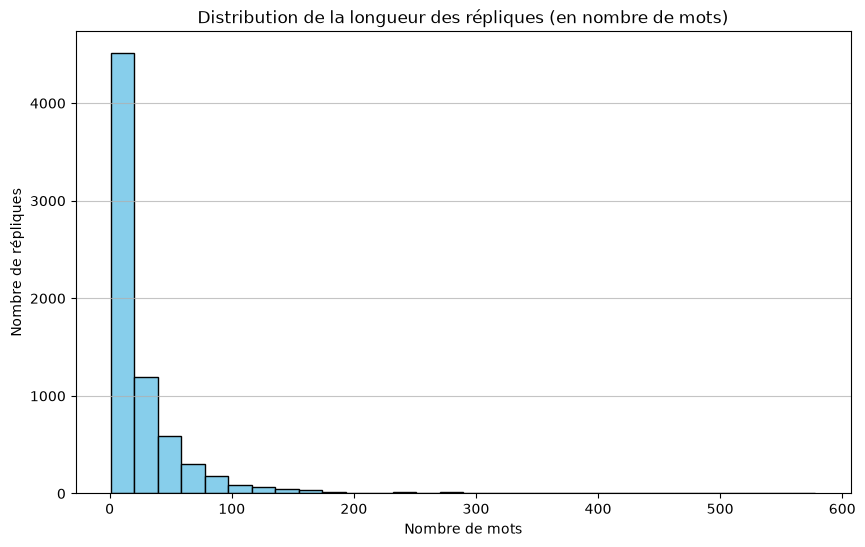

In [28]:
# TODO : afficher les 20 locuteurs les plus fréquents et leur nombre de répliques
# TODO : afficher la distribution de la longueur des répliques (en nombre de mots)
#        -> médiane, moyenne, et un histogramme
print("\n--- 20 locuteurs les plus fréquents ---\n")
print(df['locuteur'].value_counts().head(20))
print("\n--- 20 locuteurs les moins fréquents ---\n")
print(df['locuteur'].value_counts().tail(20))
print("\n--- Nombre de locuteurs avec une seule réplique ---\n")
print((df['locuteur'].value_counts() == 1).sum())

print("\n--- Distribution de la longueur des répliques (en nombre de mots) ---\n")
df['longueur_replique'] = df['replique'].apply(lambda x: len(x.split())) # Ajoute une colonne avec la longueur de chaque réplique en nombre de mots
print(df['longueur_replique'].describe())
plt.figure(figsize=(10, 6))
plt.hist(df['longueur_replique'], bins=30, color='skyblue', edgecolor='black')
plt.title("Distribution de la longueur des répliques (en nombre de mots)")
plt.xlabel("Nombre de mots")
plt.ylabel("Nombre de répliques")
plt.grid(axis='y', alpha=0.75)

**Questions :**

1. La distribution des locuteurs est-elle équilibrée ? Que se passerait-il si vous gardiez les 297 locuteurs ?
2. Quelle est la longueur médiane d'une réplique ? Est-ce beaucoup pour de la classification de texte ?
3. Quelle conséquence cette longueur aura-t-elle sur votre vecteur TF–IDF ?

> *Vos réponses :*
>
> 1. La distribution des locuteurs est déséquilibrée, certains locuteurs sont beaucoup plus représentés que d’autres. Si on gardait les 297 locuteurs, le modèle serait biaisé car nous avons peu d'exemples pour la majorité des classes (51 locuteurs ont 1 réplique). Il rique de favoriser les classes majoritaires et de mal généraliser sur les classes minoritaires.
> 2. La longueur médiane d'une réplique est de 14 mots, ce qui est court pour de la classification de texte (une phrase standard en anglais compte en moyenne entre 15 et 20 mots). Chaque réplique contient donc peu de contexte et d’indices permettant d’identifier son locuteur.
> 3. Les vecteurs TF–IDF seront très creux car une réplique contient peu de mots par rapport au vocabulaire total, donc la plupart des composantes seront nulles. Ces textes courts fournissent peu d’indices lexicaux, ce qui rendra classification difficile.

## 4. Définir la tâche

À vous de poser le problème. Vous devez décider :

- **combien de locuteurs** vous gardez (le nombre de classes) ;
- s'il faut **filtrer les répliques trop courtes**, et à partir de quel seuil ;
- si vos classes sont suffisamment **équilibrées** pour que l'accuracy ait un sens.

Il n'y a pas une seule bonne réponse. Il y a des choix, et ils doivent être **justifiés et écrits**.

> **Votre choix et sa justification :**
>
> - Nombre de locuteurs retenus : 10 locuteurs avec pour but de prédire le locuteur à partir de la réplique, avec assez d’exemples par classe. J'ai retenus les plus fréquents après filtrage (voir ci-dessous).
> - Seuil de longueur minimale : au moins 10 mots pour conserver davantage de contexte lexical, en acceptant de réduire le nombre d’exemples (se rapprocher de la longueur médiane de 14 mots et de la moyenne des phrases en anglais). Cela permet d’avoir des répliques plus longues et donc plus d’indices lexicaux pour identifier le locuteur.
> - Pourquoi : cela permet de garantir un équilibrage de 962 répliques, de 78 à 129 par classe. Avec une classe majoritaire représentant 13,4 % (ce qui est moins qu'en choisissant un seuil de 5 avec 10 locuteurs). Le déséquilibre est donc modéré et l’accuracy est un indicateur pertinent pour évaluer le modèle.

(voir la cellule suivante pour les détails).

In [21]:
longueurs = df['replique'].str.split().str.len() # Longueur de chaque réplique en nombre de mots
comparaisons = []
for seuil in (5, 10):
    frequences = df.loc[longueurs >= seuil, 'locuteur'].value_counts() # Nb répliques par locuteur pour les répliques d'au moins `seuil` mots
    for n in (5, 10, 20):
        effectifs = frequences.head(n) # Nb répliques pour les `n` locuteurs les plus fréquents
        comparaisons.append({
            'Seuil minimal (mots)': seuil,
            'Locuteurs': len(effectifs),
            'Répliques': effectifs.sum(),
            'Effectifs min–max': f'{effectifs.min()}–{effectifs.max()}',
            'Classe majoritaire (%)': round(100 * effectifs.max() / effectifs.sum(), 1),
            'Distribution': effectifs.tolist(),
        })

comparaisons = pd.DataFrame(comparaisons)
with pd.option_context('display.max_colwidth', None):
    display(comparaisons)


,Seuil minimal (mots),Locuteurs,Répliques,Effectifs min–max,Classe majoritaire (%),Distribution
0,5,5,761,126–196,25.8,"[196, 165, 141, 133, 126]"
1,5,10,1318,107–196,14.9,"[196, 165, 141, 133, 126, 116, 115, 110, 109, 107]"
2,5,20,2194,78–196,8.9,"[196, 165, 141, 133, 126, 116, 115, 110, 109, 107, 99, 98, 95, 95, 86, 83, 82, 80, 80, 78]"
3,10,5,550,94–129,23.5,"[129, 125, 107, 95, 94]"
4,10,10,962,78–129,13.4,"[129, 125, 107, 95, 94, 87, 85, 82, 80, 78]"
5,10,20,1581,54–129,8.2,"[129, 125, 107, 95, 94, 87, 85, 82, 80, 78, 75, 71, 66, 62, 61, 60, 58, 57, 55, 54]"


In [24]:
# TODO : construire `donnees`, un DataFrame filtré contenant :
#          - colonne 'replique' : le texte
#          - colonne 'locuteur' : l'étiquette
#
# Contraintes :
#   - ne garder que les N locuteurs les plus fréquents (choisissez N)
#   - écarter les répliques trop courtes (choisissez le seuil)

seuil = 10  # Seuil de longueur de réplique (en nombre de mots)
nb_locuteurs = 10  # Nb locuteurs les plus fréquents à conserver
locuteurs = df.loc[longueurs >= seuil, 'locuteur'].value_counts().head(nb_locuteurs).index # Liste des locuteurs les plus fréquents

donnees = df.loc[
    (longueurs >= seuil) & (df['locuteur'].isin(locuteurs)), # Si seuil respecté et locuteur dans la liste
    ['replique', 'locuteur']
].copy() # Copie car on va modifier le DataFrame

print(donnees['locuteur'].value_counts())
print(f"\n{len(donnees)} exemples retenus")

locuteur
GLOUCESTER         129
DUKE VINCENTIO     125
MENENIUS           107
PETRUCHIO           95
ROMEO               94
CORIOLANUS          87
JULIET              85
LEONTES             82
ISABELLA            80
KING RICHARD II     78
Name: count, dtype: int64

962 exemples retenus


## 5. ⚠️ Découper AVANT toute transformation

**C'est le point le plus important du TP.**

Tout composant qui **apprend quelque chose à partir des données** doit être ajusté sur le train seulement :

| Composant | Ce qu'il apprend en regardant les données |
|---|---|
| Vocabulaire TF–IDF | quels mots existent, et quelle colonne chacun occupe |
| Poids IDF | dans combien de documents chaque mot apparaît |
| Normalisation | la moyenne et l'écart-type de chaque variable |

Si vous vectorisez avant de découper, les fréquences du test participent au calcul de l'IDF. Votre modèle a alors utilisé une information issue du test : **votre score final sera surestimé et ne voudra plus rien dire.**

La discipline tient en deux lignes :

```python
X_train = vectorizer.fit_transform(train)   # fit + transform
X_test  = vectorizer.transform(test)        # transform SEULEMENT
```

Pensez à **stratifier** le découpage : sans cela, un locuteur peu représenté peut être absent du test.

In [33]:
# TODO : découper en train / test
#   - 20 % pour le test
#   - stratifier sur le locuteur
#   - random_state=RANDOM_STATE pour que vos résultats soient reproductibles

X_train, X_test, y_train, y_test = train_test_split(
    donnees['replique'], donnees['locuteur'],
    test_size=0.2, stratify=donnees['locuteur'], random_state=RANDOM_STATE # stratify conserve la proportion de chaque locuteur dans les deux ensembles (train et test)
)

print(f"train : {len(X_train)} exemples")
print(f"test  : {len(X_test)} exemples")

# Classes
classes = y_train.unique()
print(f"Classes : {classes}")

# Verification de la stratification
print("\n--- Vérification de la stratification ---\n")
train_counts = y_train.value_counts()
test_counts = y_test.value_counts()
stratification_check = pd.DataFrame({
    'Train': train_counts,
    'Test': test_counts,
    'Train (%)': 100 * train_counts / len(y_train),
    'Test (%)': 100 * test_counts / len(y_test),
})
print(stratification_check) 

train : 769 exemples
test  : 193 exemples
Classes : <StringArray>
[     'CORIOLANUS',      'GLOUCESTER',       'PETRUCHIO',         'LEONTES',
          'JULIET',           'ROMEO',  'DUKE VINCENTIO', 'KING RICHARD II',
        'ISABELLA',        'MENENIUS']
Length: 10, dtype: str

--- Vérification de la stratification ---

                 Train  Test  Train (%)   Test (%)
locuteur                                          
CORIOLANUS          70    17   9.102731   8.808290
DUKE VINCENTIO     100    25  13.003901  12.953368
GLOUCESTER         103    26  13.394018  13.471503
ISABELLA            64    16   8.322497   8.290155
JULIET              68    17   8.842653   8.808290
KING RICHARD II     62    16   8.062419   8.290155
LEONTES             66    16   8.582575   8.290155
MENENIUS            85    22  11.053316  11.398964
PETRUCHIO           76    19   9.882965   9.844560
ROMEO               75    19   9.752926   9.844560


## 6. Représenter le texte

Vous allez transformer chaque réplique en vecteur TF–IDF.

`TfidfVectorizer` expose plusieurs paramètres qui sont autant de décisions de prétraitement. Regardez au moins ceux-ci et **choisissez consciemment** :

| Paramètre | Question qu'il pose |
|---|---|
| `lowercase` | la casse porte-t-elle du signal pour votre tâche ? |
| `ngram_range` | faut-il récupérer un peu d'ordre local avec des bigrammes ? |
| `min_df` | à partir de combien d'occurrences un mot mérite-t-il une colonne ? |
| `max_df` | faut-il écarter les mots omniprésents ? |
| `stop_words` | ⚠️ attention au piège vu en cours |
| `sublinear_tf` | 10 occurrences valent-elles vraiment 10 fois 1 occurrence ? |

> **Vos choix et leur justification :**
>
> - **`lowercase=True` :** Regroupe les variantes de casse pour éviter des variables distinctes pour un même mot (ex. "The" et "the", réduire le nombre de features).
> - **`ngram_range=(1, 2)` :** Représente les mots seuls et les expressions de deux mots, qui pourrait aider dans notre cas à distinguer les locuteurs (ex. "I am" vs "I have").
> - **`min_df=2` :** Conserve les termes présents dans au moins deux répliques d’entraînement pour réduire les variables propres à une seule réplique (ex. "I am the king" ne créer pas de colonne pour "king" si c'est la seule réplique qui le contient).
> - **`max_df=1.0` :** Conserve les termes fréquents, car leur usage peut contribuer à identifier les locuteurs.
> - **`stop_words=None` :** Supprime pas systématiquement les pronoms, négations et mots grammaticaux, qui peuvent porter des indices de style.
> - **`sublinear_tf=True` :** Sert à atténuer l’influence des répétitions dans une réplique en remplaçant la fréquence par `1 + log(tf)`.

(j'ai choisis ces paramètres en me basant sur le SOTA de la fonction TF-IDF et sur le cours, je modifierai plus tard en fonction des résultats obtenus).

In [36]:
# TODO : instancier le vectoriseur, l'ajuster sur le train, transformer les deux jeux

vectoriseur = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=1.0,
    stop_words=None,
    sublinear_tf=True,
)

Xtr = vectoriseur.fit_transform(X_train)  # fit_transform sur le train
Xte = vectoriseur.transform(X_test)  # transform sur le test

print(f"Taille du vocabulaire : {len(vectoriseur.vocabulary_):,}")
print(f"Matrice train : {Xtr.shape}")
print(f"Matrice test  : {Xte.shape}")
print(f"Sparsité : {Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1]):.4%} de valeurs non nulles")

Taille du vocabulaire : 5,915
Matrice train : (769, 5915)
Matrice test  : (193, 5915)
Sparsité : 0.8338% de valeurs non nulles


**Questions :**

1. Quelle proportion de votre matrice est constituée de zéros ? Pourquoi est-ce structurellement inévitable ?
2. Que se passerait-il si vous stockiez cette matrice en tableau NumPy dense ?
3. Affichez les 15 termes ayant le poids IDF le plus élevé, puis les 15 plus faibles. Le résultat vous surprend-il ?

> *Vos réponses :*
>
> 1. La proportion de zéros est très élevée (plus de 99 %). C'est structurellement inévitable car chaque réplique contient peu de mots par rapport au vocabulaire, donc la plupart des features seront nulles.
> 2. Si on stockait cette matrice en tableau NumPy dense, cela consommerait énormément de mémoire et serait inefficace. La plupart des valeurs étant nulles, il est préférable d'utiliser une représentation creuse (sparse) pour économiser de l'espace et accélérer les calculs.
> 3. Pour les termes ayant le poids IDF le plus faible, pas de surprise, les mots les plus fréquents sont des mots grammaticaux (ex. "the", "and", "to") qui apparaissent dans presque toutes les répliques. Pour les termes ayant le poids IDF le plus élevé, ce sont des mots rares ou spécifiques à certains locuteurs (ex. "lived") mais on voit aussi des bigrammes apparaitre (ex. "ll bring") ce qui est surprenant car on pourrait s'attendre à ce que les bigrammes soient plus fréquents et donc aient un IDF plus faible.

In [30]:
# TODO : afficher les 15 termes de plus fort et de plus faible IDF
#        (indice : vectoriseur.idf_ et vectoriseur.get_feature_names_out())

idf_values = vectoriseur.idf_  # Récupère les valeurs IDF
# Trie les indices des valeurs IDF pour obtenir les 15 plus faibles et les 15 plus fortes
indices_plus_faibles = np.argsort(idf_values)[:15]
indices_plus_fortes = np.argsort(idf_values)[-15:]

print("\n--- 15 termes avec IDF le plus faible ---\n")
for idx in indices_plus_faibles:
    print(f"{vectoriseur.get_feature_names_out()[idx]} : {idf_values[idx]:.4f}")

print("\n--- 15 termes avec IDF le plus élevé ---\n")
for idx in indices_plus_fortes:
    print(f"{vectoriseur.get_feature_names_out()[idx]} : {idf_values[idx]:.4f}")




--- 15 termes avec IDF le plus faible ---

the : 1.5261
and : 1.5371
to : 1.5506
of : 1.8352
that : 1.8626
you : 1.9527
in : 1.9800
my : 2.0224
not : 2.0480
is : 2.0934
me : 2.1209
with : 2.1370
for : 2.1451
it : 2.2083
be : 2.2214

--- 15 termes avec IDF le plus élevé ---

lived : 6.5478
ll bring : 6.5478
ll go : 6.5478
ll have : 6.5478
ll hear : 6.5478
ll no : 6.5478
ll say : 6.5478
ll try : 6.5478
ll turn : 6.5478
loathed : 6.5478
lodge : 6.5478
loins : 6.5478
long and : 6.5478
light love : 6.5478
youthful : 6.5478


## 7. Modéliser

### 7.1 D'abord la baseline — sans exception

Une baseline vous donne le **plancher** : le score qu'on atteint sans rien apprendre.

Sans elle, vous ne pouvez pas savoir si 65 % est un bon résultat ou un résultat catastrophique. C'est un réflexe professionnel, pas une formalité pédagogique.

In [ ]:
# TODO : entraîner un DummyClassifier (strategy='most_frequent' puis 'stratified')
#        et afficher son accuracy et son F1 macro sur le test

# most_frequent: prédire toujours la classe majoritaire (la plus fréquente dans le train)
# stratified: prédire aléatoirement en respectant la distribution des classes dans le train

for strategie in ('most_frequent', 'stratified'):
    baseline = DummyClassifier(strategy=strategie, random_state=RANDOM_STATE)
    baseline.fit(Xtr, y_train)
    predictions = baseline.predict(Xte)

    accuracy = accuracy_score(y_test, predictions)
    f1 = f1_score(y_test, predictions, average='macro', zero_division=0)
    print(f"{strategie} : accuracy = {accuracy:.3f}, F1 = {f1:.3f}")

most_frequent : accuracy = 0.135, F1 = 0.024
stratified : accuracy = 0.119, F1 = 0.115


> **Score de la baseline :**
>
> Tout modèle qui ne dépasse pas nettement ce score n'apprend rien d'utile.

### 7.2 Au moins deux modèles

Choisissez-en au moins deux parmi : `MultinomialNB`, `LogisticRegression`, `LinearSVC`.

Pour chacun, notez **pourquoi** il est adapté (ou non) à une représentation TF–IDF très creuse et de grande dimension.

⚠️ Vos classes sont probablement déséquilibrées. Regardez ce que fait `class_weight='balanced'` et dites si vous le gardez.

> **Vos choix et leur justification :**
>
> J'ai choisi d'utiliser `LogisticRegression` et `LinearSVC` car à partir de notre cours on sait que pour des datasets de grande dimension et creux, ces modèles sont les plus adaptés.

In [41]:
# TODO : entraîner au moins deux modèles et stocker leurs prédictions
#        Suggestion : un dictionnaire {nom_du_modele: predictions}

# class_weight=None pour ne pas compenser le déséquilibre des classes (car il est modéré)

modeles = {
    'LogisticRegression': LogisticRegression(max_iter=1000, class_weight=None),
    'LinearSVC': LinearSVC(
        max_iter=5000, class_weight=None, random_state=RANDOM_STATE
    ),
}

resultats = {}
for nom, modele in modeles.items():
    modele.fit(Xtr, y_train)
    resultats[nom] = modele.predict(Xte)


## 8. Évaluer et analyser

### 8.1 Les métriques

Rappel du cours : sur des classes déséquilibrées, **l'accuracy ment**. Reportez toujours le F1, et précisez la méthode d'agrégation.

- `average='macro'` : moyenne non pondérée sur les classes → traite les classes rares à égalité
- `average='weighted'` : pondérée par les effectifs → dominée par les classes fréquentes

Indiquez explicitement laquelle vous utilisez et pourquoi.

In [ ]:
# TODO : pour chaque modèle, afficher accuracy, précision, rappel et F1 (macro et weighted)
#        puis un classification_report complet
#        Présentez la comparaison sous forme de tableau (DataFrame)

scores = []
for nom, predictions in resultats.items():
    ligne = {'Modèle': nom, 'Accuracy': accuracy_score(y_test, predictions)}
    for moyenne in ('macro', 'weighted'):
        ligne[f'Précision {moyenne}'] = precision_score(
            y_test, predictions, average=moyenne, zero_division=0)
        ligne[f'Rappel {moyenne}'] = recall_score(
            y_test, predictions, average=moyenne, zero_division=0)
        ligne[f'F1 {moyenne}'] = f1_score(
            y_test, predictions, average=moyenne, zero_division=0)
    scores.append(ligne)
    print(f"\n{nom}")
    print(classification_report(y_test, predictions, digits=3, zero_division=0))

comparaison = pd.DataFrame(scores).set_index('Modèle')
display(comparaison.round(3))


LogisticRegression
                 precision    recall  f1-score   support

     CORIOLANUS      0.778     0.412     0.538        17
 DUKE VINCENTIO      0.300     0.600     0.400        25
     GLOUCESTER      0.354     0.654     0.459        26
       ISABELLA      0.800     0.250     0.381        16
         JULIET      0.462     0.353     0.400        17
KING RICHARD II      0.750     0.188     0.300        16
        LEONTES      1.000     0.438     0.609        16
       MENENIUS      0.500     0.500     0.500        22
      PETRUCHIO      0.316     0.316     0.316        19
          ROMEO      0.375     0.316     0.343        19

       accuracy                          0.425       193
      macro avg      0.563     0.403     0.425       193
   weighted avg      0.532     0.425     0.425       193


LinearSVC
                 precision    recall  f1-score   support

     CORIOLANUS      0.667     0.706     0.686        17
 DUKE VINCENTIO      0.457     0.640     0.533       

,Accuracy,Précision macro,Rappel macro,F1 macro,Précision weighted,Rappel weighted,F1 weighted
Modèle,,,,,,,
LogisticRegression,0.425,0.563,0.403,0.425,0.532,0.425,0.425
LinearSVC,0.565,0.574,0.558,0.563,0.571,0.565,0.565


### 8.2 La matrice de confusion

Affichez-la pour votre meilleur modèle. **Une matrice affichée sans commentaire ne vaut rien** — c'est la partie 8.3 qui compte.

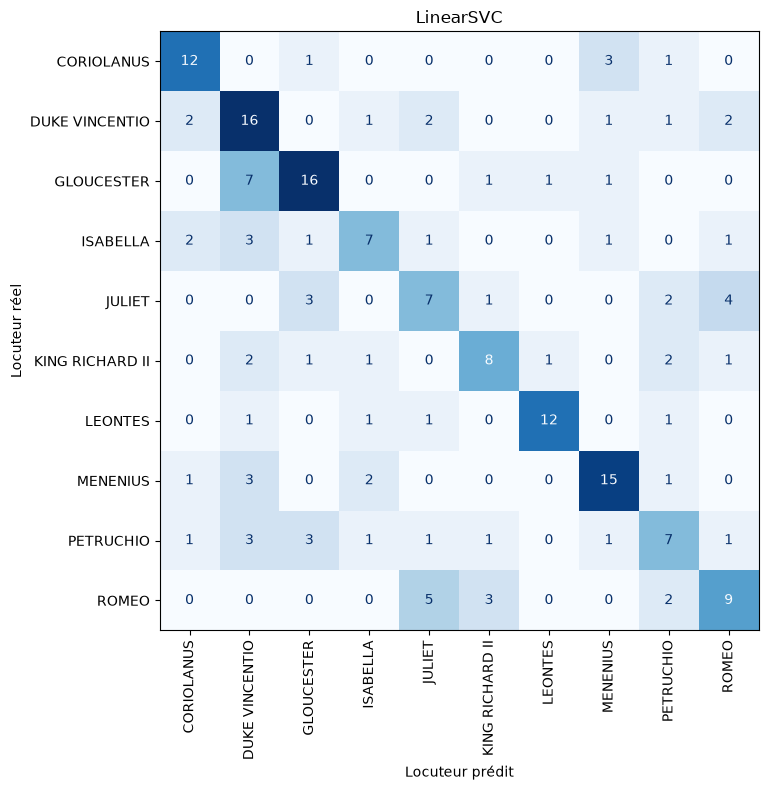

In [ ]:
# TODO : afficher la matrice de confusion du meilleur modèle
#        (indice : ConfusionMatrixDisplay.from_predictions)

meilleur = comparaison['F1 macro'].idxmax() # Choix meilleur modèle selon le F1 macro

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, resultats[meilleur],
    cmap='Blues', values_format='d', xticks_rotation=90,
    colorbar=False, ax=ax,
)
ax.set(title=meilleur, xlabel='Locuteur prédit', ylabel='Locuteur réel')
plt.tight_layout()
plt.show()

> *Analyse des résultats :*
> - **Reconnaissance inégale :** le rappel atteint 75 % pour LEONTES avec 12/16 répliques correctement classées, on peut donc considérer que le modèle a appris à reconnaître le vocabulaire de ce locuteur. Par contre, il atteint 36,8 % pour PETRUCHIO et 41,2 % pour JULIET, on peut donc considérer que le modèle a plus de mal à reconnaître le vocabulaire de ces locuteurs (vocabulaire moins distinctif). 
> - **Locuteurs JULIET et ROMEO :** 4 répliques de JULIET sont attribuées à ROMEO, et 5 de ROMEO à JULIET. Leur vocabulaire ou un contexte partagé pourrait expliquer ces confusions.
> - **Locuteurs GLOUCESTER et DUKE VINCENTIO :** 7 répliques de GLOUCESTER sont attribuées à DUKE VINCENTIO, sans erreur dans le sens inverse. Certains indices lexicaux pourraient favoriser la prédiction de DUKE VINCENTIO.
> - **DUKE VINCENTIO est trop souvent prédit :** 35 prédictions pour 25 répliques réelles, avec seulement 16 prédictions correctes, soit une précision de 45,7 %.


### 8.3 Analyse des erreurs — la partie la plus importante

Répondez précisément, en vous appuyant sur des exemples concrets tirés de vos données.

1. **Quelles paires de locuteurs sont le plus confondues ?** Formulez une hypothèse : viennent-ils de la même pièce ? ont-ils un registre proche ? un nombre d'exemples très différent ?

2. **Sortez cinq répliques mal classées et lisez-les.** Auriez-vous su répondre vous-même ? Si non, que dit cela sur le plafond de performance atteignable ?

3. **Regardez les coefficients de votre modèle linéaire** (`coef_`) : quels termes pèsent le plus pour chaque classe ? Y a-t-il des **noms propres** parmi eux ?

   Si oui, posez-vous la vraie question : votre modèle reconnaît-il le **style d'un personnage**, ou identifie-t-il simplement la **pièce** dans laquelle la réplique apparaît ? Ce n'est pas du tout la même tâche, et cela change ce que vous pouvez affirmer sur votre modèle.

4. **Votre score est-il crédible ?** Reprenez votre pipeline et vérifiez qu'aucune information du test n'a pu remonter vers l'entraînement.

In [9]:
# Les quinze premières erreurs de LinearSVC, dans l’ordre du test.
erreurs_svc = pd.DataFrame({
    'Réplique': X_test,
    'Locuteur réel': y_test,
    'Locuteur prédit': resultats['LinearSVC'],
})
erreurs_svc = erreurs_svc.loc[erreurs_svc['Locuteur réel'] != erreurs_svc['Locuteur prédit']] # Filtrer les erreurs (réel != prédit)
with pd.option_context('display.max_colwidth', None):
    display(erreurs_svc.head(15))


,Réplique,Locuteur réel,Locuteur prédit
3009,"And I'll still stay, to have thee still forget, Forgetting any other home but this.",ROMEO,JULIET
3338,"O God!--O nurse, how shall this be prevented? My husband is on earth, my faith in heaven; How shall that faith return again to earth, Unless that husband send it me from heaven By leaving earth? comfort me, counsel me. Alack, alack, that heaven should practise stratagems Upon so soft a subject as myself! What say'st thou? hast thou not a word of joy? Some comfort, nurse.",JULIET,ROMEO
2294,"I am in health, I breathe, and see thee ill.",KING RICHARD II,PETRUCHIO
3344,"Well, thou hast comforted me marvellous much. Go in: and tell my lady I am gone, Having displeased my father, to Laurence' cell, To make confession and to be absolved.",JULIET,ROMEO
2875,"Not I, believe me: you have dancing shoes With nimble soles: I have a soul of lead So stakes me to the ground I cannot move.",ROMEO,JULIET
3378,"Love give me strength! and strength shall help afford. Farewell, dear father!",JULIET,ROMEO
2300,"Right, you say true: as Hereford's love, so his; As theirs, so mine; and all be as it is.",KING RICHARD II,LEONTES
1323,"Your eyes drop millstones, when fools' eyes drop tears: I like you, lads; about your business straight; Go, go, dispatch.",GLOUCESTER,DUKE VINCENTIO
6229,Who knows not where a wasp does wear his sting? In his tail.,PETRUCHIO,GLOUCESTER
1579,"I say, without characters, fame lives long. Thus, like the formal vice, Iniquity, I moralize two meanings in one word.",GLOUCESTER,MENENIUS


In [10]:
# Les dix poids positifs les plus élevés pour chaque locuteur.
termes_svc = vectoriseur.get_feature_names_out() # Récupère les termes du vocabulaire
coefficients_svc = []
for locuteur, poids in zip(modeles['LinearSVC'].classes_, modeles['LinearSVC'].coef_):
    indices = np.argsort(poids)[::-1] # Trie les indices des poids par ordre décroissant
    indices = indices[poids[indices] > 0][:10] # 10 poids positifs les plus élevés
    coefficients_svc.append({
        'Locuteur': locuteur,
        'Termes et poids': [(termes_svc[i], round(float(poids[i]), 3)) for i in indices],
    })
coefficients_svc = pd.DataFrame(coefficients_svc).set_index('Locuteur')
with pd.option_context('display.max_colwidth', None):
    display(coefficients_svc)


,Termes et poids
Locuteur,
CORIOLANUS,"[(them, 1.401), (rome, 1.038), (voices, 0.841), (volsces, 0.811), (their, 0.778), (again, 0.768), (in rome, 0.749), (hurt, 0.731), (my, 0.724), (aufidius, 0.721)]"
DUKE VINCENTIO,"[(provost, 1.472), (angelo, 1.293), (you, 1.287), (duke, 1.193), (the duke, 1.146), (friar, 1.119), (himself, 1.1), (him, 1.016), (claudio, 0.994), (your, 0.92)]"
GLOUCESTER,"[(clarence, 1.45), (king, 1.313), (edward, 1.213), (the king, 1.051), (shore, 0.925), (lord, 0.903), (warwick, 0.895), (imprisonment, 0.839), (well, 0.832), (myself, 0.825)]"
ISABELLA,"[(my brother, 1.805), (brother, 1.469), (heaven, 1.254), (but, 0.872), (your honour, 0.82), (yes, 0.811), (alas, 0.734), (most, 0.706), (as, 0.705), (pluck, 0.696)]"
JULIET,"[(romeo, 1.623), (love, 0.958), (may be, 0.944), (nurse, 0.889), (learn, 0.785), (have thee, 0.74), (then have, 0.731), (on my, 0.723), (my true, 0.689), (hands, 0.686)]"
KING RICHARD II,"[(king, 1.3), (bolingbroke, 1.217), (our, 1.118), (cousin, 1.088), (high, 0.908), (make, 0.831), (sorrow, 0.784), (yours and, 0.751), (norfolk, 0.696), (uncle, 0.672)]"
LEONTES,"[(paulina, 1.447), (camillo, 1.211), (her, 0.936), (perform, 0.859), (bastard, 0.812), (at my, 0.792), (she, 0.725), (polixenes, 0.725), (hermione, 0.706), (thou, 0.65)]"
MENENIUS,"[(marcius, 1.674), (work, 1.172), (he, 1.15), (what then, 0.953), (speak, 0.925), (cominius, 0.89), (be gone, 0.844), (noble, 0.832), (you, 0.816), (tribunes, 0.814)]"
PETRUCHIO,"[(kate, 2.645), (signior, 1.033), (father, 0.939), (and, 0.935), (her, 0.922), (knock, 0.914), (now by, 0.824), (gown, 0.794), (cap, 0.715), (blow, 0.697)]"


> *Votre analyse :*
>
>1. Comme dit avant, je vois des confusions entre JULIET et ROMEO car 4 répliques de JULIET sont attribuées à ROMEO et 5 dans le sens inverse. Leurs effectifs sont proches, avec 85 et 94 répliques dans le jeu retenu (donc équilibrés). Ils partagent la même pièce (Romeo and Juliet) et le terme « love » a un poids élevé pour les deux classes (il peut donc exister un biais autour de ce terme dans la prédiction). Pour GLOUCESTER et DUKE VINCENTIO, les 7 confusions vont toutes vers DUKE. Leurs effectifs sont aussi proches (129 et 125) donc le déséquilibre des classes ne suffit pas à expliquer cela. Des mots partagés pourraient favoriser DUKE (pour l'exemple n°1241, le "you" coef 1.287 chez DUKE intervient 4 fois et "him", coef 1.016, aussi).
>
>2. Je pense pas que j’aurais identifié les cinq locuteurs avec certitude sans contexte. Dans les exemples 2 et 4, « nurse », « husband » et « Laurence » donnent des indices sur la réplique. Les exemples 1 et 5 expriment des sentiments qui pourraient appartenir à plusieurs personnages. L’exemple 3, « I am in health, I breathe, and see thee ill », reste très général. La difficulté d’identifier un locuteur à partir d’un texte isolé est élevée (ce qui va dans mon sens de choisir au moins 10 mots comme seuil).
>
>3. On voit plusieurs noms propres : « kate » pour PETRUCHIO (2,645), « romeo » pour JULIET (1,623), et « paulina » et « camillo » pour LEONTES (1,447 et 1,211). Le modèle s’appuie donc en partie sur les personnages mentionnés dans les répliques et le contexte de l’histoire. Ces indices aident à reconnaître une pièce ou les interlocuteurs d’un personnage.
>
>4. L'accuracy de 56,5 % est la première, et pour l'instant la meilleure, estimation pour les répliques retenues dans ce corpus. Le découpage est avant le TF–IDF donc vocabulaire et poids IDF viennent uniquement du train, et le test passe par transform. Aucune réplique identique n’est présente dans les deux ensembles. Le test reste petit et les deux ensembles viennent du même corpus. J’ai aussi retenu LinearSVC d’après les scores du test : le résultat reste exploratoire.


## 9. Pour aller plus loin (optionnel)

Si vous avez terminé :

- **Validation croisée.** Remplacez le simple découpage par un `cross_val_score` en 5 folds sur le train. Regardez la **dispersion** des scores, pas seulement la moyenne. Un modèle à 0,82 ± 0,01 vaut souvent mieux qu'un modèle à 0,84 ± 0,09.

- **Comparer les représentations.** `CountVectorizer` (Bag of Words) contre `TfidfVectorizer`. L'écart est-il significatif ? Correspond-il à ce que le cours laissait prévoir ?

- **Faire varier la difficulté.** Passez de 5 à 10 locuteurs. Comment évoluent l'accuracy et le F1 macro ? Lequel des deux chute le plus, et pourquoi ?

- **Sur-apprentissage.** Comparez votre score sur le train et sur le test. L'écart vous dit-il quelque chose ? Que se passe-t-il quand vous faites varier `C` dans la régression logistique ?

- **Utiliser un `Pipeline` scikit-learn.** Encapsulez vectoriseur et modèle dans un `sklearn.pipeline.Pipeline`. Expliquez en une phrase pourquoi cette construction rend la fuite de données structurellement impossible.

## Rendu

Notebook exécuté, avec toutes les sorties visibles et **toutes les cellules de réponse remplies**.

Le barème porte autant sur la justification de vos choix et sur l'analyse des erreurs que sur le score obtenu.